In [6]:
from google.colab import drive
drive.mount('/content/drive')


import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/VisionGuard/data/visionguard_data.zip"
DEST_PATH = "/content/data"


os.makedirs(DEST_PATH, exist_ok=True)


print("Extracting dataset...")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DEST_PATH)

print("Extraction completed!")

DATASET_PATH = os.path.join(
    DEST_PATH, "data", "raw"
)

AI_PATH = os.path.join(
    DATASET_PATH, "AiArtData", "AiArtData"
)

REAL_PATH = os.path.join(
    DATASET_PATH, "RealArt", "RealArt"
)

print("\nDataset Verification")
print("-" * 40)

for cls, path in [
    ("AiArtData", AI_PATH),
    ("RealArt", REAL_PATH)
]:

    if os.path.exists(path):

        images = [
            f for f in os.listdir(path)
            if os.path.isfile(os.path.join(path, f))
        ]

        print(f"{cls}: {len(images)} images")

    else:
        print(f"{cls}: Folder not found!")
        print(f"Expected path: {path}")

print("-" * 40)
print("Dataset verification completed!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting dataset...
Extraction completed!

Dataset Verification
----------------------------------------
AiArtData: 539 images
RealArt: 436 images
----------------------------------------
Dataset verification completed!


In [7]:
import os, random, shutil
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, f1_score)


SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TF version: 2.21.0
GPUs: []


In [8]:

from pathlib import Path
from sklearn.model_selection import train_test_split
import csv

# Updated dataset paths
DATA_DIR = Path("/content/data/data/raw")

CLASSES = ["AiArtData", "RealArt"]
LABEL_MAP = {"AiArtData": 1, "RealArt": 0}  # 1 = AI, 0 = Real

all_paths, all_labels = [], []

# Load images from nested class folders
for cls in CLASSES:

    class_dir = DATA_DIR / cls / cls

    for f in class_dir.iterdir():
        if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}:
            all_paths.append(str(f))
            all_labels.append(LABEL_MAP[cls])

# 70 / 15 / 15 split -- stratified
X_train, X_temp, y_train, y_temp = train_test_split(
    all_paths,
    all_labels,
    test_size=0.30,
    stratify=all_labels,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print(f"Train : {len(X_train)} | Val : {len(X_val)} | Test : {len(X_test)}")

# Save split lists as CSV
for name, paths, labels in [
    ("train", X_train, y_train),
    ("val", X_val, y_val),
    ("test", X_test, y_test)
]:
    with open(f"/content/{name}_split.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["path", "label"])
        w.writerows(zip(paths, labels))

print("Split CSVs saved.")

Train : 681 | Val : 146 | Test : 146
Split CSVs saved.


Pipeline ready.
  Image size : 224x224
  Batch size : 32
  Aspect ratio handling: tf.image.resize stretches to exactly 224x224, distorting aspect ratio slightly. Acceptable for classification tasks.


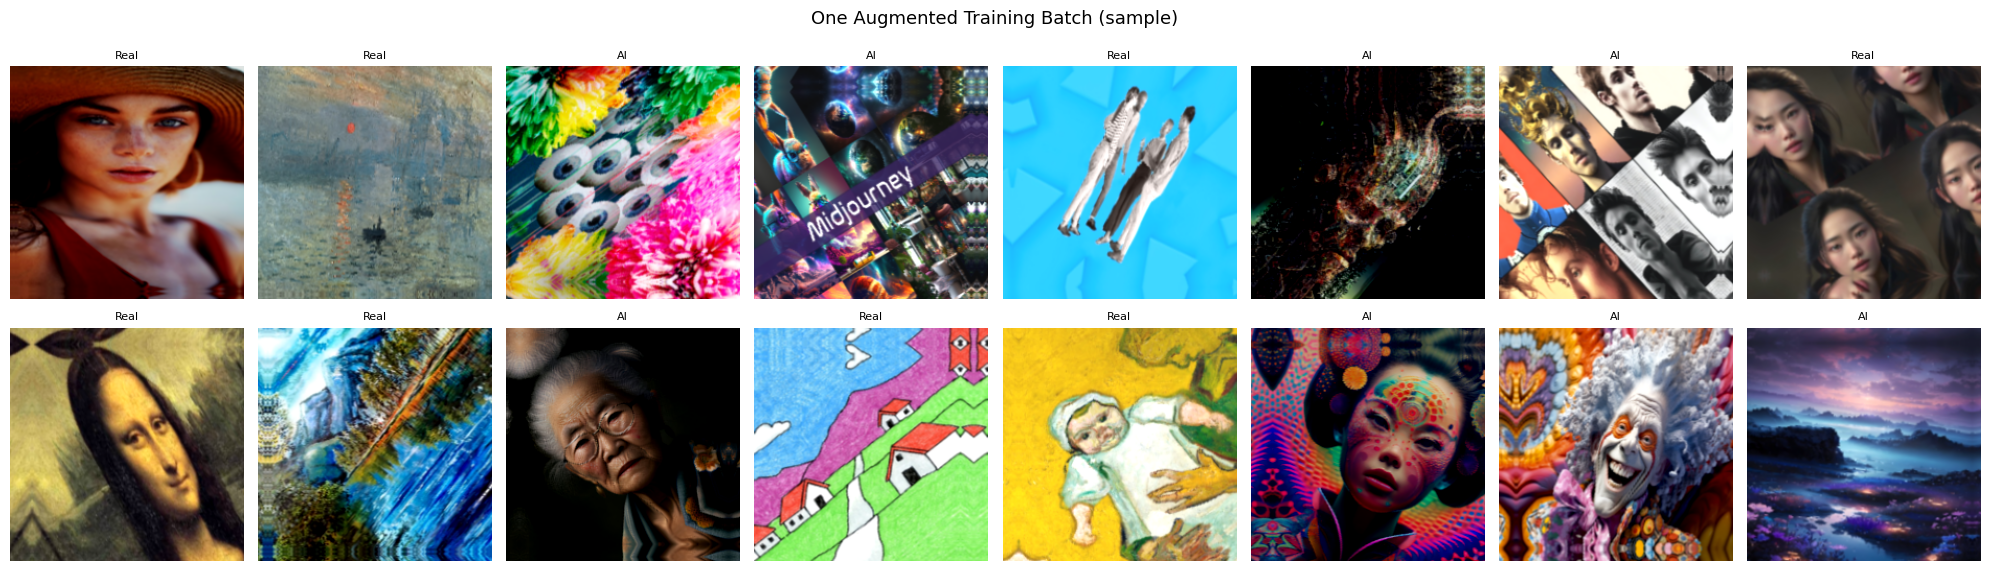

Saved augmented_batch.png


In [9]:
IMG_SIZE  = 224      # EfficientNetB0 expects 224x224
BATCH     = 32

def decode_image(path, label):
    """Read file → decode → resize to 224x224 → float32 in [0,1]."""
    raw   = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    # resize returns float32; clip in case of minor overshoot
    image = tf.clip_by_value(image, 0.0, 255.0)
    return image, label

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    ),
    tf.keras.layers.RandomBrightness(0.15),
    tf.keras.layers.RandomContrast(0.20),
], name="augmentation")


def augment_image(image, label):
    image = augment(image, training=True)
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
            (list(paths), list(labels)))
    ds = ds.map(decode_image,    num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.shuffle(buffer_size=512, seed=SEED)
    ds = ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds   = make_dataset(X_val,   y_val,   training=False)
test_ds  = make_dataset(X_test,  y_test,  training=False)

print("Pipeline ready.")
print(f"  Image size : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Batch size : {BATCH}")
print(f"  Aspect ratio handling: tf.image.resize stretches to exactly "
      f"{IMG_SIZE}x{IMG_SIZE}, distorting aspect ratio slightly. "
      f"Acceptable for classification tasks.")

# Visualise one augmented batch (Task 2.1 figure)
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(2, 8, figsize=(20, 6))
fig.suptitle("One Augmented Training Batch (sample)", fontsize=13)
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy().astype("uint8"))
    ax.set_title("AI" if labels[i] == 1 else "Real", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/augmented_batch.png", dpi=120)
plt.show()
print("Saved augmented_batch.png")

In [32]:
from tensorflow.keras import layers, models
from tensorflow.keras import regularizers

def build_cnn():

    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Normalise pixels to [-1, 1]
    x = layers.Rescaling(1./127.5, offset=-1)(inputs)

    # Block 1
    x = layers.Conv2D(
        32, 3,
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Block 2
    x = layers.Conv2D(
        64, 3,
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Block 3
    x = layers.Conv2D(
        128, 3,
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Block 4
    x = layers.Conv2D(
        256, 3,
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    # Dense layer
    x = layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    # Increased dropout
    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        kernel_regularizer=regularizers.l2(3e-4)
    )(x)

    model = models.Model(inputs, outputs, name="VisionGuard_CNN")

    return model

cnn_model = build_cnn()
cnn_model.summary()

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.AUC(name="auc")]
)

Model: "VisionGuard_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 456,385 (1.74 MB)

 Trainable params: 455,425 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

2026/11/07 10:06:46 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'fc7de8388d1d448aa3dd910a0d0f15fe', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current tensorflow workflow


Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5490 - auc: 0.5786 - loss: 0.8032 - precision: 0.5925 - recall: 0.5860
Epoch 1: val_loss improved from None to 0.74647, saving model to /content/models/cnn_best.keras

Epoch 1: finished saving model to /content/models/cnn_best.keras


22/22 ━━━━━━━━━━━━━━━━━━━━ 125s 5s/step - accuracy: 0.5859 - auc: 0.6122 - loss: 0.7925 - precision: 0.6273 - recall: 0.6207 - val_accuracy: 0.5000 - val_auc: 0.6251 - val_loss: 0.7465 - val_precision: 0.6053 - val_recall: 0.2840 - learning_rate: 0.0010
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6320 - auc: 0.6523 - loss: 0.7580 - precision: 0.6558 - recall: 0.7185
Epoch 2: val_loss did not improve from 0.74647
22/22 ━━━━━━━━━━━━━━━━━━━━ 120s 5s/step - accuracy: 0.6153 - auc: 0.6547 - loss: 0.7473 - precision: 0.6386 - recall: 0.7029 - val_accuracy: 0.4452 - val_auc: 0.6863 - val_loss: 0.8144 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6671 - auc: 0.7015 - loss: 0.7135 - precision: 0.6886 - recall: 0.6967
Epoch 3: val_loss did not improve from 0.74647
22/22 ━━━━━━━━━━━━━━━━━━━━ 124s 5s/step - accuracy: 0.6505 - auc: 0.6851 - loss: 0.7216 - precision: 0.6883 - recall: 0.67

2026/11/07 10:20:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run upset-doe-808 at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1/runs/fc7de8388d1d448aa3dd910a0d0f15fe
🧪 View experiment at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1


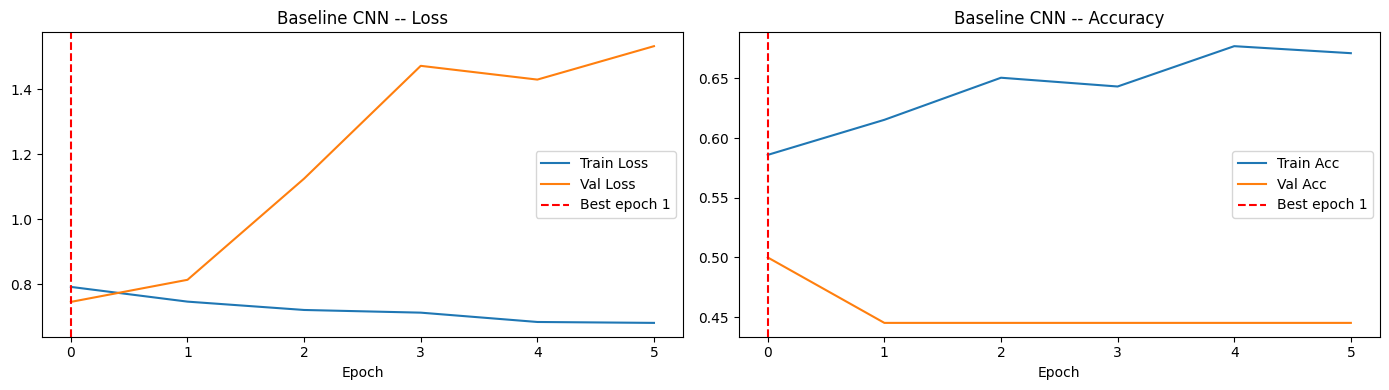

Best epoch: 1


In [33]:
os.makedirs("/content/models", exist_ok=True)

callbacks_cnn = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/models/cnn_best.keras",
        monitor="val_loss", save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5,
        patience=3, min_lr=1e-6, verbose=1),
]

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_cnn,
    verbose=1
)

# Plot training curves
def plot_history(history, title, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    best_epoch = np.argmin(history.history["val_loss"])

    axes[0].plot(history.history["loss"],     label="Train Loss")
    axes[0].plot(history.history["val_loss"], label="Val Loss")
    axes[0].axvline(best_epoch, color="red",
                    linestyle="--", label=f"Best epoch {best_epoch+1}")
    axes[0].set_title(f"{title} -- Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history.history["accuracy"],     label="Train Acc")
    axes[1].plot(history.history["val_accuracy"], label="Val Acc")
    axes[1].axvline(best_epoch, color="red",
                    linestyle="--", label=f"Best epoch {best_epoch+1}")
    axes[1].set_title(f"{title} -- Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(save_path, dpi=120)
    plt.show()
    print(f"Best epoch: {best_epoch + 1}")

plot_history(history_cnn, "Baseline CNN", "/content/cnn_curves.png")

In [34]:
import numpy as np

y_prob = cnn_model.predict(val_ds).ravel()

print("Minimum probability:", np.min(y_prob))
print("Maximum probability:", np.max(y_prob))
print("Mean probability:", np.mean(y_prob))
print("Median probability:", np.median(y_prob))

print("\nAI images - average probability:")

y_true = np.concatenate([
    labels.numpy().ravel()
    for _, labels in val_ds
])

print(np.mean(y_prob[y_true == 1]))

print("\nReal images - average probability:")
print(np.mean(y_prob[y_true == 0]))

4/5 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step
Minimum probability: 0.4360524
Maximum probability: 0.5195621
Mean probability: 0.48591468
Median probability: 0.48896816

AI images - average probability:
0.48957127

Real images - average probability:
0.48135802


In [35]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = 224

# Load pretrained EfficientNetB0
base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build classifier
inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(128, activation="relu")(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

efficient_model = models.Model(inputs, outputs)

# Compile
efficient_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

efficient_model.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [36]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/models/efficientnet_best.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history_eff = efficient_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

2026/11/07 10:23:12 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '4964546acb3d4a88818d0943655ccdac', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current tensorflow workflow


Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5806 - auc: 0.6062 - loss: 0.6945 - precision: 0.6019 - recall: 0.7051

22/22 ━━━━━━━━━━━━━━━━━━━━ 72s 2s/step - accuracy: 0.6270 - auc: 0.6726 - loss: 0.6501 - precision: 0.6352 - recall: 0.7666 - val_accuracy: 0.6644 - val_auc: 0.7462 - val_loss: 0.5892 - val_precision: 0.7105 - val_recall: 0.6667 - learning_rate: 0.0010
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7035 - auc: 0.7859 - loss: 0.5658 - precision: 0.7501 - recall: 0.6603

22/22 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.7137 - auc: 0.7906 - loss: 0.5508 - precision: 0.7446 - recall: 0.7347 - val_accuracy: 0.7055 - val_auc: 0.8042 - val_loss: 0.5555 - val_precision: 0.6696 - val_recall: 0.9259 - learning_rate: 0.0010
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7944 - auc: 0.8766 - loss: 0.4509 - precision: 0.7886 - recall: 0.8588

22/22 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.8062 - auc: 0.8780 - loss: 0.4431 - precision: 0.8133 - recall: 0.8435 - val_accuracy: 0.7808 - val_auc: 0.8400 - val_loss: 0.5035 - val_precision: 0.7526 - val_recall: 0.9012 - learning_rate: 0.0010
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7915 - auc: 0.8848 - loss: 0.4315 - precision: 0.7916 - recall: 0.8501

22/22 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.7827 - auc: 0.8780 - loss: 0.4365 - precision: 0.7974 - recall: 0.8143 - val_accuracy: 0.7534 - val_auc: 0.8525 - val_loss: 0.4849 - val_precision: 0.7320 - val_recall: 0.8765 - learning_rate: 0.0010
Epoch 5/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7975 - auc: 0.8896 - loss: 0.4192 - precision: 0.7917 - recall: 0.8512

22/22 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.8120 - auc: 0.8960 - loss: 0.4072 - precision: 0.8184 - recall: 0.8488 - val_accuracy: 0.8014 - val_auc: 0.8573 - val_loss: 0.4795 - val_precision: 0.7955 - val_recall: 0.8642 - learning_rate: 0.0010
Epoch 6/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8141 - auc: 0.9042 - loss: 0.3988 - precision: 0.8254 - recall: 0.8507

22/22 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step - accuracy: 0.8106 - auc: 0.8982 - loss: 0.4030 - precision: 0.8212 - recall: 0.8408 - val_accuracy: 0.8151 - val_auc: 0.8606 - val_loss: 0.4615 - val_precision: 0.8140 - val_recall: 0.8642 - learning_rate: 0.0010
Epoch 7/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.8370 - auc: 0.9211 - loss: 0.3601 - precision: 0.8519 - recall: 0.8541 - val_accuracy: 0.7877 - val_auc: 0.8609 - val_loss: 0.4773 - val_precision: 0.7660 - val_recall: 0.8889 - learning_rate: 0.0010
Epoch 8/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.8561 - auc: 0.9304 - loss: 0.3393 - precision: 0.8479 - recall: 0.9019 - val_accuracy: 0.7945 - val_auc: 0.8568 - val_loss: 0.4683 - val_precision: 0.8148 - val_recall: 0.8148 - learning_rate: 0.0010
Epoch 9/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.8546 - auc: 0.9232 - loss: 0.3535 - precision: 0.8475 - recall: 0.8992 - val_accuracy: 0.8014 - val_auc: 0.8563 - val_loss: 0.4688 - val_precision: 0.7889 

2026/11/07 10:36:23 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run auspicious-roo-455 at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1/runs/4964546acb3d4a88818d0943655ccdac
🧪 View experiment at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1


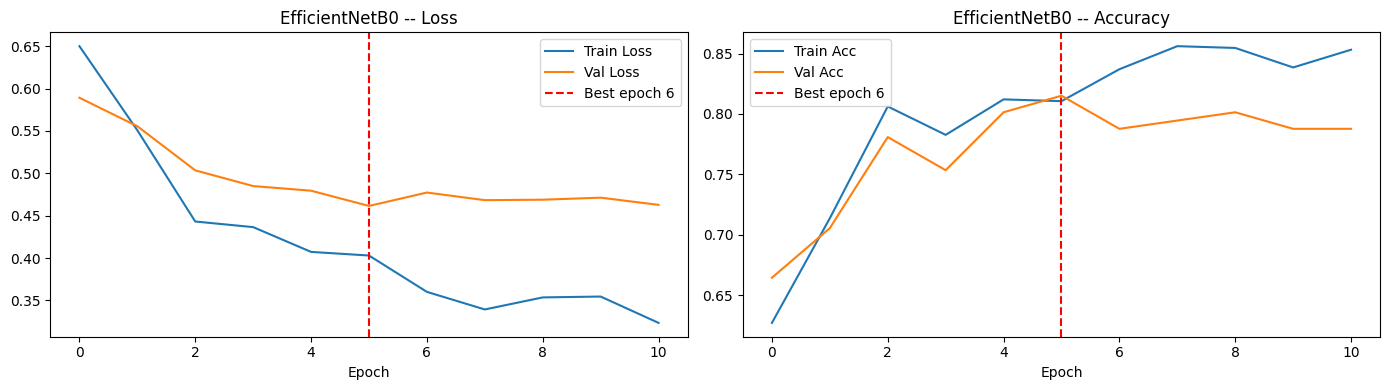

Best epoch: 6


In [37]:
plot_history(
    history_eff,
    "EfficientNetB0",
    "/content/efficientnet_curves.png"
)

In [39]:
test_results = efficient_model.evaluate(test_ds)

for name, value in zip(efficient_model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.7397 - auc: 0.8245 - loss: 0.5084 - precision: 0.7792 - recall: 0.7407
loss: 0.5084
compile_metrics: 0.7397


5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step


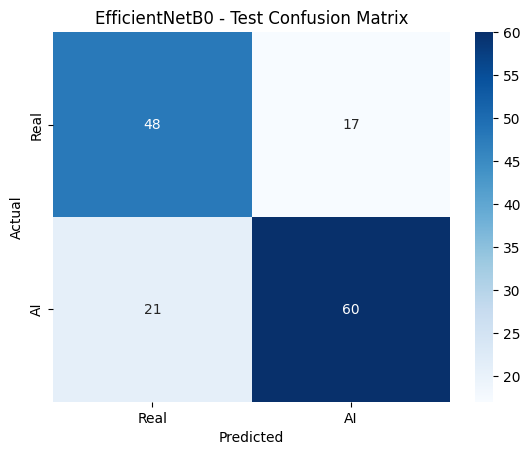

              precision    recall  f1-score   support

        Real       0.70      0.74      0.72        65
          AI       0.78      0.74      0.76        81

    accuracy                           0.74       146
   macro avg       0.74      0.74      0.74       146
weighted avg       0.74      0.74      0.74       146



In [41]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Actual labels
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

# Predicted probabilities
y_probs = efficient_model.predict(test_ds).flatten()

# Convert probabilities into classes
y_pred = (y_probs >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real", "AI"],
    yticklabels=["Real", "AI"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNetB0 - Test Confusion Matrix")
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=["Real", "AI"]
))

Stage 1 model saved successfully!
Trainable layers in base: 13
['block7a_expand_conv', 'block7a_expand_bn', 'block7a_expand_activation', 'block7a_dwconv', 'block7a_bn', 'block7a_activation', 'block7a_se_squeeze', 'block7a_se_reshape', 'block7a_se_reduce', 'block7a_se_expand']


2026/11/07 11:00:38 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'bc1e77614fb84292a3a2eec80271f2ba', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current tensorflow workflow


Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8079 - auc: 0.8711 - loss: 0.4614 - precision: 0.8725 - recall: 0.7581
Epoch 1: val_loss improved from None to 0.46475, saving model to /content/models/eff_stage2_best.keras

Epoch 1: finished saving model to /content/models/eff_stage2_best.keras


22/22 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.8267 - auc: 0.8948 - loss: 0.4256 - precision: 0.8889 - recall: 0.7851 - val_accuracy: 0.8014 - val_auc: 0.8607 - val_loss: 0.4648 - val_precision: 0.8023 - val_recall: 0.8519 - learning_rate: 1.0000e-05
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8137 - auc: 0.8979 - loss: 0.4239 - precision: 0.8788 - recall: 0.7823
Epoch 2: val_loss did not improve from 0.46475
22/22 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.8238 - auc: 0.9020 - loss: 0.4127 - precision: 0.8661 - recall: 0.8064 - val_accuracy: 0.8014 - val_auc: 0.8572 - val_loss: 0.4698 - val_precision: 0.8023 - val_recall: 0.8519 - learning_rate: 1.0000e-05
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8162 - auc: 0.8896 - loss: 0.4261 - precision: 0.8487 - recall: 0.7998
Epoch 3: val_loss did not improve from 0.46475
22/22 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.8091 - auc: 0.8760 - loss: 0.4442 - precision: 0.8421 - recall: 0.8064 

2026/11/07 11:08:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run bald-bee-919 at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1/runs/bc1e77614fb84292a3a2eec80271f2ba
🧪 View experiment at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1


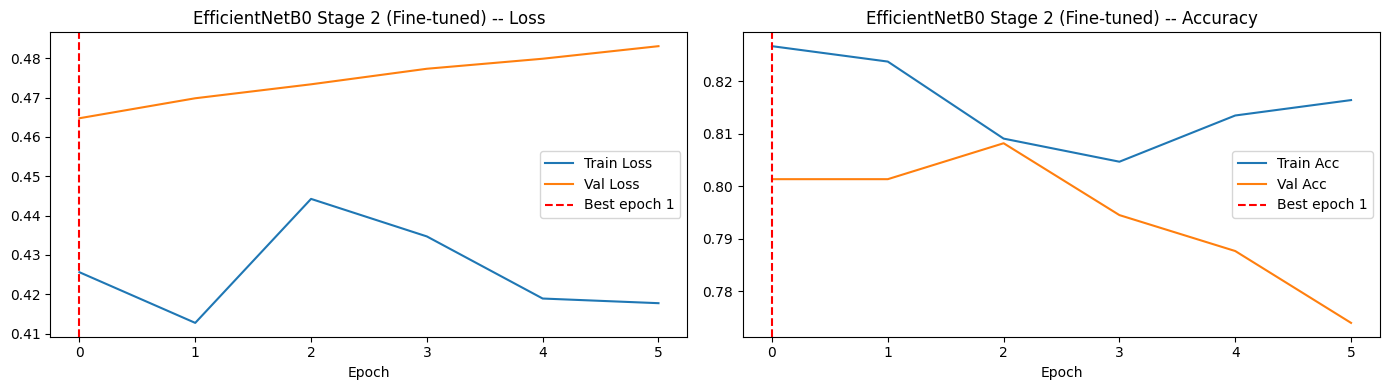

Best epoch: 1


In [43]:
import tensorflow as tf
import os


os.makedirs("/content/models", exist_ok=True)

# Preserve Stage 1 model by saving it directly
efficient_model.save("/content/models/eff_stage1_saved.keras")
print("Stage 1 model saved successfully!")

# Unfreeze EfficientNet base
# Accessing the base layer directly from our functional model
# The first active layer after Input is usually the pre-trained base
eff_base = efficient_model.layers[1]
eff_base.trainable = True

# Freeze everything except block7
for layer in eff_base.layers:
    if "block7" in layer.name:
        layer.trainable = True
    else:
        layer.trainable = False

# Check trainable layers
trainable_stage2 = [
    layer.name
    for layer in eff_base.layers
    if layer.trainable
]

print("Trainable layers in base:", len(trainable_stage2))
print(trainable_stage2[:10])

# Compile with a smaller learning rate
efficient_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Callbacks
callbacks_eff2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/models/eff_stage2_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# Fine-tuning
history_eff2 = efficient_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_eff2,
    verbose=1
)

# Plot training curves
plot_history(
    history_eff2,
    "EfficientNetB0 Stage 2 (Fine-tuned)",
    "/content/eff_stage2_curves.png"
)

In [44]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score,
    accuracy_score
)

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [45]:
def evaluate_model(
    model,
    model_name,
    test_ds,
    y_test,
    threshold=0.5
):

    print("\n" + "=" * 50)
    print("Evaluating:", model_name)
    print("=" * 50)

    # Predictions
    y_probs = model.predict(
        test_ds,
        verbose=0
    ).flatten()

    y_pred = (
        y_probs >= threshold
    ).astype(int)


    # Classification report
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Real", "AI-Generated"]
        )
    )


    # Metrics
    auc = roc_auc_score(
        y_test,
        y_probs
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    print("Threshold:", round(threshold, 3))
    print("Accuracy:", round(accuracy, 4))
    print("ROC-AUC:", round(auc, 4))


    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5)
    )


    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Real", "AI"],
        yticklabels=["Real", "AI"],
        ax=axes[0]
    )

    axes[0].set_title(
        f"{model_name} - Confusion Matrix"
    )

    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")


    # ROC curve
    fpr, tpr, _ = roc_curve(
        y_test,
        y_probs
    )

    axes[1].plot(
        fpr,
        tpr,
        label=f"AUC = {auc:.4f}"
    )

    axes[1].plot(
        [0, 1],
        [0, 1],
        "k--"
    )

    axes[1].set_title(
        f"{model_name} - ROC Curve"
    )

    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].legend()

    plt.tight_layout()

    save_path = (
        f"/content/{model_name.replace(' ', '_')}_eval.png"
    )

    plt.savefig(
        save_path,
        dpi=120
    )

    plt.show()


    report = classification_report(
        y_test,
        y_pred,
        target_names=["Real", "AI-Generated"],
        output_dict=True
    )

    return {
        "accuracy": accuracy,
        "precision": report["AI-Generated"]["precision"],
        "recall": report["AI-Generated"]["recall"],
        "f1": report["AI-Generated"]["f1-score"],
        "auc": auc,
        "y_probs": y_probs,
        "y_pred": y_pred
    }


In [46]:
def find_best_threshold(model, val_ds, y_val):

    val_probs = model.predict(
        val_ds,
        verbose=0
    ).flatten()

    thresholds = np.arange(
        0.30,
        0.81,
        0.01
    )

    f1_scores = [
        f1_score(
            y_val,
            (val_probs >= threshold).astype(int),
            zero_division=0
        )
        for threshold in thresholds
    ]

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]

    print("Best threshold:", round(best_threshold, 2))
    print("Validation F1:", round(f1_scores[best_index], 4))

    return best_threshold

Rebuilding Stage 1 model topology...
Loading Stage 1 weights...


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Finding best threshold for Baseline CNN...
Best threshold: 0.47
Validation F1: 0.7282
Finding best threshold for Stage 1 Model...
Best threshold: 0.48
Validation F1: 0.8452
Finding best threshold for Stage 2 (Fine-tuned) Model...
Best threshold: 0.4
Validation F1: 0.8457

Evaluating: Baseline CNN
              precision    recall  f1-score   support

        Real       0.69      0.28      0.40        65
AI-Generated       0.61      0.90      0.73        81

    accuracy                           0.62       146
   macro avg       0.65      0.59      0.56       146
weighted avg       0.65      0.62      0.58       146

Threshold: 0.47
Accuracy: 0.6233
ROC-AUC: 0.6598


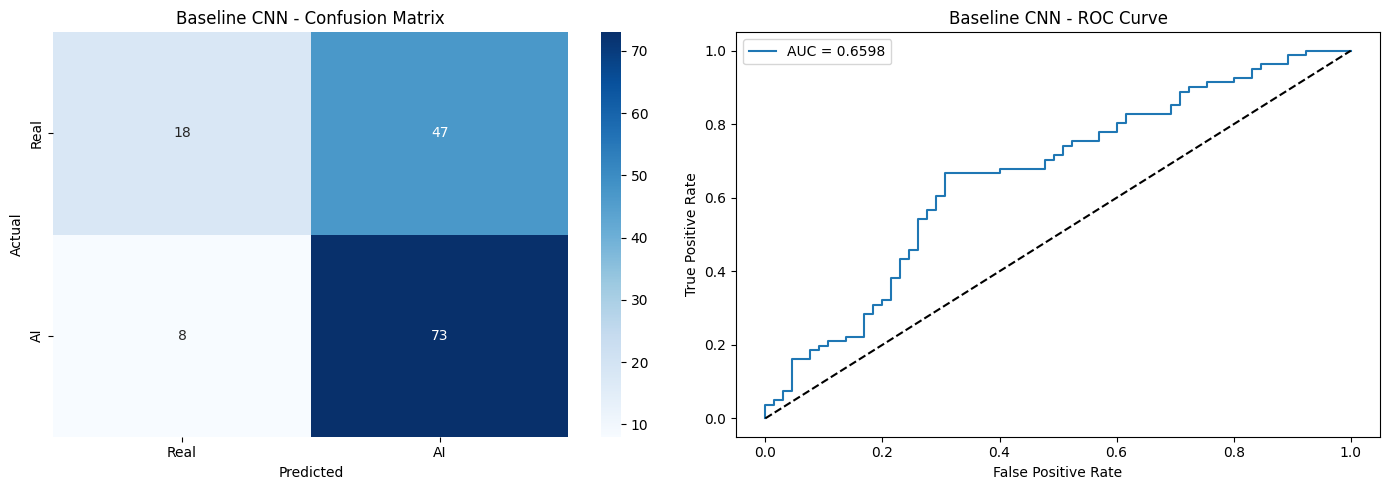


Evaluating: EfficientNet Stage 1
              precision    recall  f1-score   support

        Real       0.69      0.72      0.71        65
AI-Generated       0.77      0.74      0.75        81

    accuracy                           0.73       146
   macro avg       0.73      0.73      0.73       146
weighted avg       0.73      0.73      0.73       146

Threshold: 0.48
Accuracy: 0.7329
ROC-AUC: 0.8243


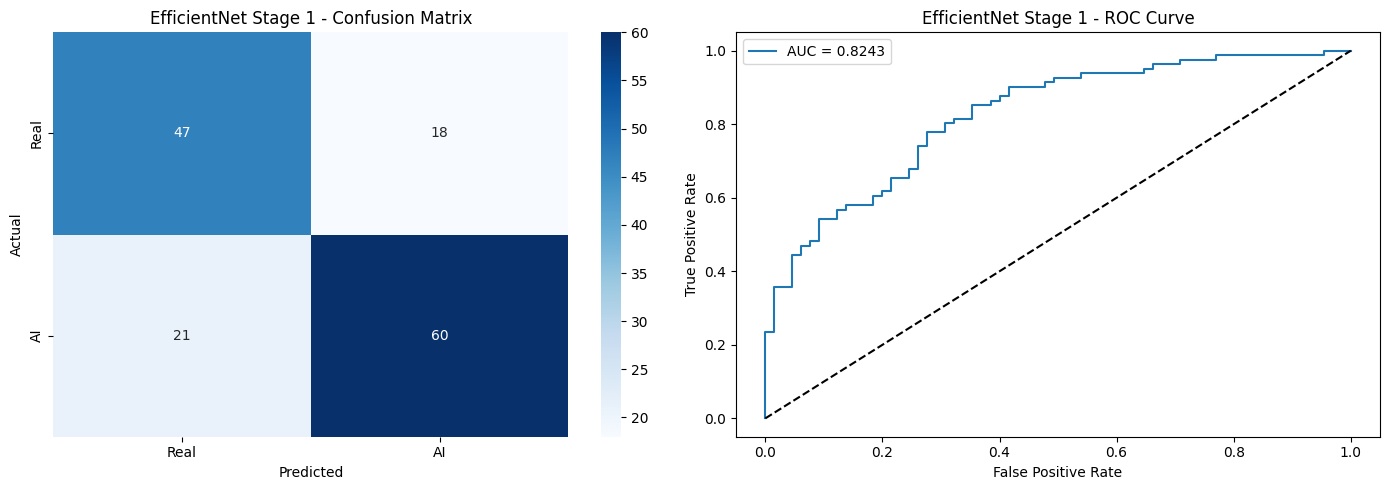


Evaluating: EfficientNet Stage 2
              precision    recall  f1-score   support

        Real       0.75      0.65      0.69        65
AI-Generated       0.74      0.83      0.78        81

    accuracy                           0.75       146
   macro avg       0.75      0.74      0.74       146
weighted avg       0.75      0.75      0.74       146

Threshold: 0.4
Accuracy: 0.7466
ROC-AUC: 0.8272


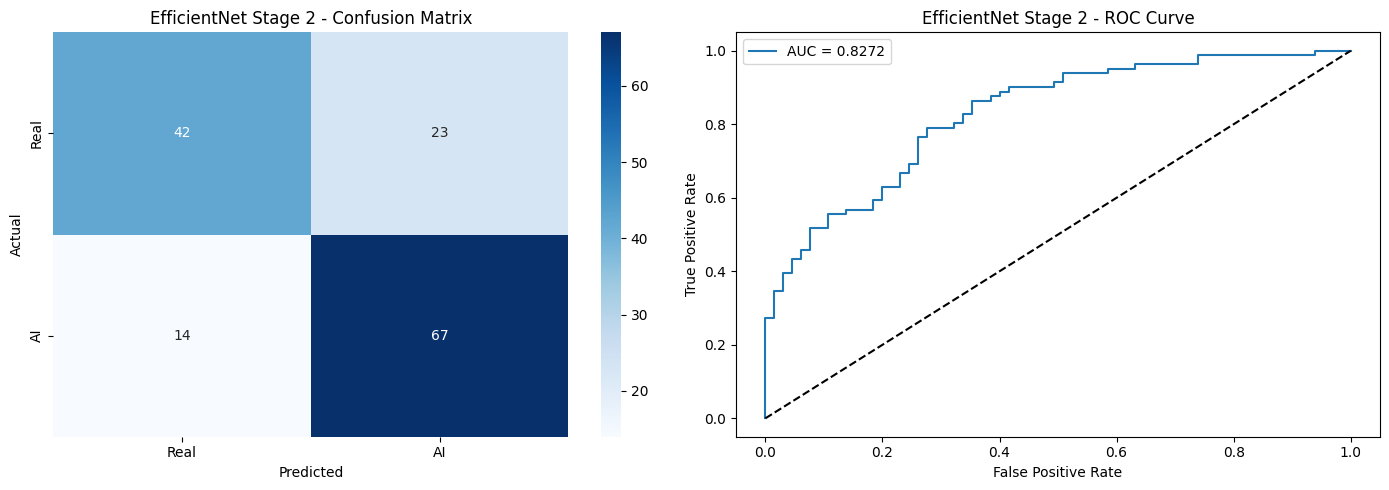

In [48]:
import tensorflow as tf
from tensorflow.keras import layers, models

print("Rebuilding Stage 1 model topology...")
# 1. Rebuild base model architecture
base_model_temp = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model_temp.trainable = False

# 2. Rebuild the custom classifier architecture with correct dimensions (128 units to match saved checkpoint)
inputs_temp = layers.Input(shape=(224, 224, 3))
x_temp = base_model_temp(inputs_temp, training=False)
x_temp = layers.GlobalAveragePooling2D()(x_temp)
x_temp = layers.Dropout(0.4)(x_temp)
x_temp = layers.Dense(128, activation="relu")(x_temp)
x_temp = layers.Dropout(0.3)(x_temp)
outputs_temp = layers.Dense(1, activation="sigmoid")(x_temp)

stage1_model = models.Model(inputs_temp, outputs_temp)

# 3. Compile the template stage 1 model
stage1_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# 4. Load the weights from the saved checkpoint to restore Stage 1 state
print("Loading Stage 1 weights...")
stage1_model.load_weights("/content/models/eff_stage1_saved.keras")

# Reference Stage 2 model
eff_model = efficient_model

# Find thresholds using validation data
print("Finding best threshold for Baseline CNN...")
cnn_threshold = find_best_threshold(
    cnn_model,
    val_ds,
    y_val
)

print("Finding best threshold for Stage 1 Model...")
stage1_threshold = find_best_threshold(
    stage1_model,
    val_ds,
    y_val
)

print("Finding best threshold for Stage 2 (Fine-tuned) Model...")
stage2_threshold = find_best_threshold(
    eff_model,
    val_ds,
    y_val
)


# Evaluate CNN
cnn_results = evaluate_model(
    cnn_model,
    "Baseline CNN",
    test_ds,
    y_test,
    cnn_threshold
)


# Evaluate EfficientNet Stage 1
stage1_results = evaluate_model(
    stage1_model,
    "EfficientNet Stage 1",
    test_ds,
    y_test,
    stage1_threshold
)


# Evaluate EfficientNet Stage 2
stage2_results = evaluate_model(
    eff_model,
    "EfficientNet Stage 2",
    test_ds,
    y_test,
    stage2_threshold
)

In [49]:
print("\nMODEL COMPARISON")

print(
    f"{'Metric':<12}"
    f"{'CNN':>12}"
    f"{'Stage 1':>12}"
    f"{'Stage 2':>12}"
)

for metric in [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc"
]:

    print(
        f"{metric:<12}"
        f"{cnn_results[metric]:>12.4f}"
        f"{stage1_results[metric]:>12.4f}"
        f"{stage2_results[metric]:>12.4f}"
    )


MODEL COMPARISON
Metric               CNN     Stage 1     Stage 2
accuracy          0.6233      0.7329      0.7466
precision         0.6083      0.7692      0.7444
recall            0.9012      0.7407      0.8272
f1                0.7264      0.7547      0.7836
auc               0.6598      0.8243      0.8272


Total misclassified images: 37


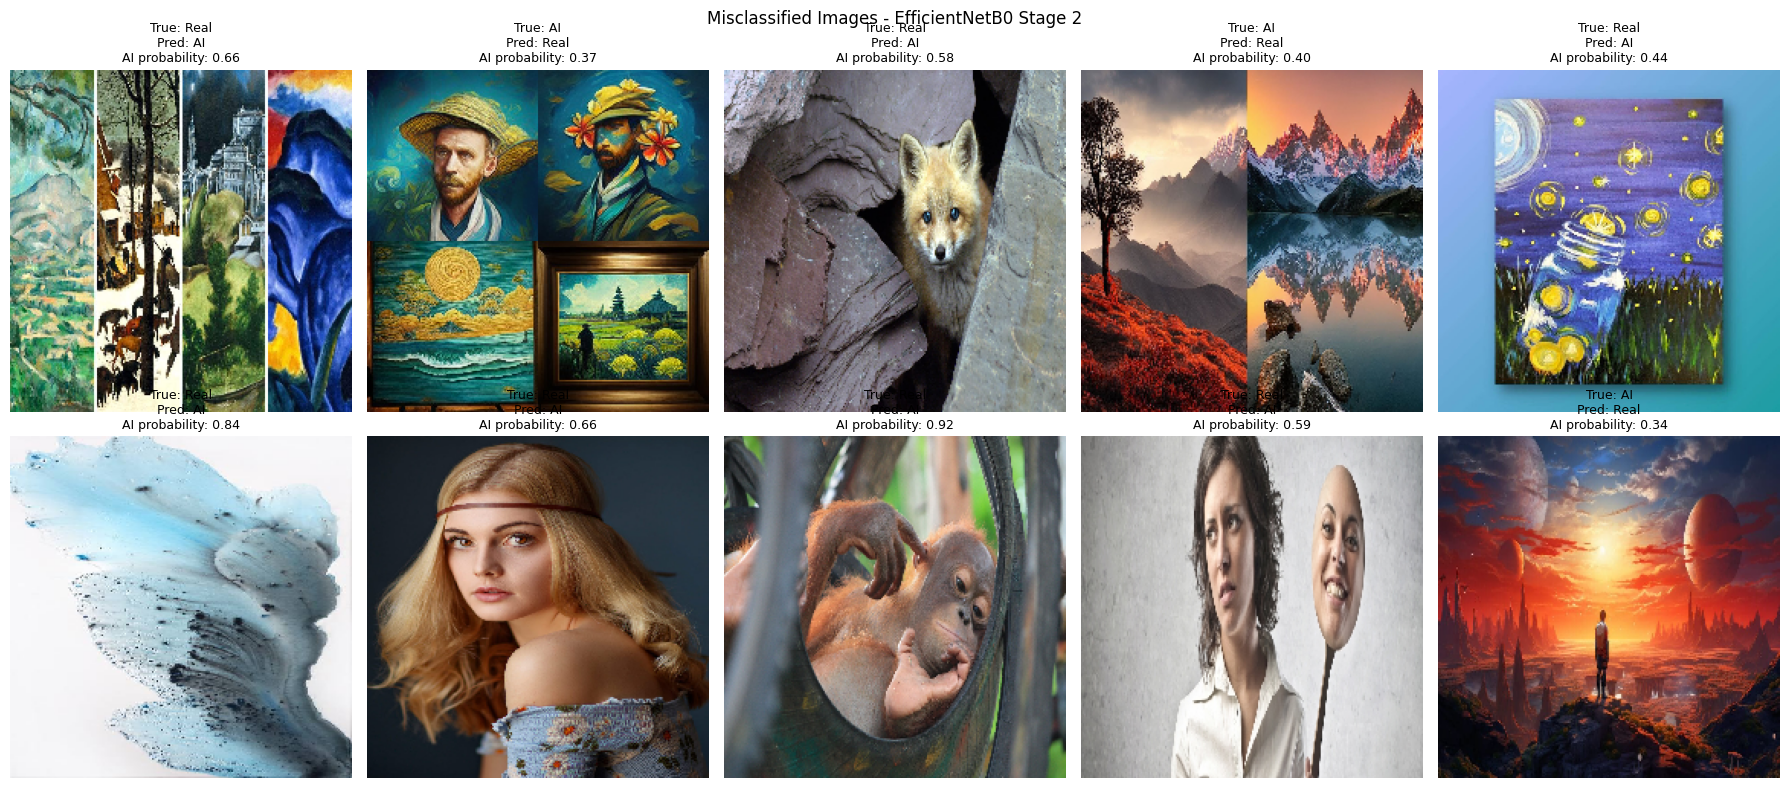

In [50]:
# Find incorrectly classified images
misclassified_idx = np.where(
    stage2_results["y_pred"] != np.array(y_test)
)[0]

print(
    "Total misclassified images:",
    len(misclassified_idx)
)


# Display up to 10 mistakes
num_images = min(
    10,
    len(misclassified_idx)
)

if num_images > 0:

    fig, axes = plt.subplots(
        2,
        5,
        figsize=(18, 8)
    )

    axes = axes.flatten()

    fig.suptitle(
        "Misclassified Images - EfficientNetB0 Stage 2"
    )

    for i in range(10):
        axes[i].axis("off")

    for i, idx in enumerate(
        misclassified_idx[:num_images]
    ):

        img = tf.keras.utils.load_img(
            X_test[idx],
            target_size=(IMG_SIZE, IMG_SIZE)
        )

        true_label = (
            "AI" if y_test[idx] == 1 else "Real"
        )

        pred_label = (
            "AI"
            if stage2_results["y_pred"][idx] == 1
            else "Real"
        )

        confidence = stage2_results["y_probs"][idx]

        axes[i].imshow(img)

        axes[i].set_title(
            f"True: {true_label}\n"
            f"Pred: {pred_label}\n"
            f"AI probability: {confidence:.2f}",
            fontsize=9
        )

    plt.tight_layout()

    plt.savefig(
        "/content/misclassified.png",
        dpi=120
    )

    plt.show()

else:
    print("No misclassified images!")

In [51]:
!pip install -q keras-tuner

import keras_tuner as kt

In [52]:
(x_toy, y_toy), (x_test_toy, y_test_toy) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

x_toy = x_toy.astype("float32") / 255.0

x_toy = x_toy[..., np.newaxis]


def toy_model_builder(hp):

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(28, 28, 1)
        ),

        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(
            units=hp.Int(
                "units",
                64,
                256,
                step=64
            ),
            activation="relu"
        ),

        tf.keras.layers.Dense(
            10,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            hp.Float(
                "lr",
                1e-4,
                1e-2,
                sampling="log"
            )
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return model


toy_tuner = kt.RandomSearch(

    toy_model_builder,

    objective="val_accuracy",

    max_trials=5,

    seed=SEED,

    directory="/content/toy_tuner",

    project_name="fashion_mnist",

    overwrite=True
)


toy_tuner.search(

    x_toy,

    y_toy,

    epochs=3,

    validation_split=0.2,

    verbose=1
)


best_toy = toy_tuner.get_best_hyperparameters(1)[0]

print("Best Toy Hyperparameters")

print("Units:", best_toy.get("units"))

print("Learning Rate:", best_toy.get("lr"))

Trial 5 Complete [00h 01m 12s]
val_accuracy: 0.8632500171661377

Best val_accuracy So Far: 0.8692499995231628
Total elapsed time: 00h 07m 29s
Best Toy Hyperparameters
Units: 256
Learning Rate: 0.000505466655750672


In [56]:
from tensorflow.keras.applications import EfficientNetB0
def vg_model_builder(hp):

    inputs = tf.keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    base = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # Number of blocks to unfreeze
    n_unfreeze = hp.Int(
        "unfreeze_blocks",
        0,
        3
    )

    base.trainable = True

    blocks = [
        f"block{7-i}"
        for i in range(n_unfreeze)
    ]

    for layer in base.layers:

        layer.trainable = any(
            block in layer.name
            for block in blocks
        )

    x = base(
        inputs,
        training=False
    )

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(
        hp.Float(
            "dropout",
            0.2,
            0.5,
            step=0.1
        )
    )(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = models.Model(
        inputs,
        outputs
    )

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            hp.Float(
                "lr",
                1e-5,
                1e-3,
                sampling="log"
            )
        ),

        loss="binary_crossentropy",

        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return model


vg_tuner = kt.RandomSearch(

    vg_model_builder,

    objective=kt.Objective(
        "val_auc",
        direction="max"
    ),

    max_trials=5,

    seed=SEED,

    directory="/content/vg_tuner",

    project_name="visionguard_random",

    overwrite=True
)


vg_tuner.search(

    train_ds,

    validation_data=val_ds,

    epochs=5,

    verbose=1
)


best_vg = vg_tuner.get_best_hyperparameters(1)[0]


print("\nBest VisionGuard Hyperparameters")

print("Learning Rate:", best_vg.get("lr"))

print("Dropout:", best_vg.get("dropout"))

print("Unfreeze Blocks:", best_vg.get("unfreeze_blocks"))

Trial 5 Complete [00h 11m 43s]
val_auc: 0.9149097800254822

Best val_auc So Far: 0.9149097800254822
Total elapsed time: 00h 43m 17s

Best VisionGuard Hyperparameters
Learning Rate: 0.0008547485565344062
Dropout: 0.2
Unfreeze Blocks: 3


In [57]:
import os
import shutil

DRIVE_OUT = "/content/drive/MyDrive/VisionGuard/outputs"

os.makedirs(
    DRIVE_OUT,
    exist_ok=True
)

In [58]:
model_candidates = {
    "CNN": cnn_model,
    "EfficientNet_Stage1": stage1_model,
    "EfficientNet_Stage2": eff_model
}

validation_scores = {
    "CNN": find_best_threshold(cnn_model, val_ds, y_val),
    "EfficientNet_Stage1": find_best_threshold(stage1_model, val_ds, y_val),
    "EfficientNet_Stage2": find_best_threshold(eff_model, val_ds, y_val)
}

print("Validation thresholds:")
print(validation_scores)

Best threshold: 0.47
Validation F1: 0.7282
Best threshold: 0.48
Validation F1: 0.8452
Best threshold: 0.4
Validation F1: 0.8457
Validation thresholds:
{'CNN': np.float64(0.47000000000000014), 'EfficientNet_Stage1': np.float64(0.48000000000000015), 'EfficientNet_Stage2': np.float64(0.4000000000000001)}


In [59]:
def get_validation_f1(model):

    probs = model.predict(
        val_ds,
        verbose=0
    ).flatten()

    preds = (probs >= 0.5).astype(int)

    return f1_score(
        y_val,
        preds,
        zero_division=0
    )


validation_f1 = {
    name: get_validation_f1(model)
    for name, model in model_candidates.items()
}

print("Validation F1 scores:", validation_f1)

best_name = max(
    validation_f1,
    key=validation_f1.get
)

champion_model = model_candidates[best_name]

print("Selected champion:", best_name)

Validation F1 scores: {'CNN': 0.3865546218487395, 'EfficientNet_Stage1': 0.8383233532934131, 'EfficientNet_Stage2': 0.8263473053892215}
Selected champion: EfficientNet_Stage1


In [60]:
# Save champion
champion_model.save(
    f"{DRIVE_OUT}/champion_model.keras"
)

# Save individual models
cnn_model.save(
    f"{DRIVE_OUT}/cnn_model.keras"
)

stage1_model.save(
    f"{DRIVE_OUT}/efficientnet_stage1.keras"
)

eff_model.save(
    f"{DRIVE_OUT}/efficientnet_stage2.keras"
)

print("All models saved!")

All models saved!


In [61]:
files_to_save = [

    "augmented_batch.png",

    "cnn_curves.png",

    "eff_stage1_curves.png",

    "eff_stage2_curves.png",

    "Baseline_CNN_eval.png",

    "EfficientNet_Stage_1_eval.png",

    "EfficientNet_Stage_2_eval.png",

    "misclassified.png",

    "train_split.csv",

    "val_split.csv",

    "test_split.csv"
]


for fname in files_to_save:

    src = f"/content/{fname}"

    if os.path.exists(src):

        shutil.copy(
            src,
            f"{DRIVE_OUT}/{fname}"
        )

    else:

        print("Not found, skipping:", fname)


print("\nAll available outputs saved to Google Drive!")

print("Output directory:", DRIVE_OUT)

Not found, skipping: eff_stage1_curves.png

All available outputs saved to Google Drive!
Output directory: /content/drive/MyDrive/VisionGuard/outputs


In [62]:
import mlflow
import mlflow.keras

# Use local MLflow for the toy demo first
mlflow.set_tracking_uri("file:///content/mlruns")
mlflow.set_experiment("toy_fashion_mnist")

for lr in [1e-3, 1e-4]:
    with mlflow.start_run(run_name=f"toy_lr_{lr}"):
        # Build and train a tiny model
        toy = tf.keras.Sequential([
            tf.keras.layers.Flatten(input_shape=(28,28,1)),
            tf.keras.layers.Dense(128, activation="relu"),
            tf.keras.layers.Dense(10, activation="softmax")
        ])
        toy.compile(
            optimizer=tf.keras.optimizers.Adam(lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        # Log parameters
        mlflow.log_param("learning_rate", lr)
        mlflow.log_param("units", 128)
        mlflow.log_param("dataset", "fashion_mnist")

        history_toy = toy.fit(
            x_toy, y_toy,
            validation_split=0.2,
            epochs=5, verbose=0
        )

        # Log per-epoch metrics manually
        for epoch, (loss, acc, val_loss, val_acc) in enumerate(zip(
            history_toy.history["loss"],
            history_toy.history["accuracy"],
            history_toy.history["val_loss"],
            history_toy.history["val_accuracy"]
        )):
            mlflow.log_metric("train_loss", loss,     step=epoch)
            mlflow.log_metric("train_acc",  acc,      step=epoch)
            mlflow.log_metric("val_loss",   val_loss, step=epoch)
            mlflow.log_metric("val_acc",    val_acc,  step=epoch)

        # Log final metric and a plot
        final_val_acc = history_toy.history["val_accuracy"][-1]
        mlflow.log_metric("final_val_acc", final_val_acc)

        fig, ax = plt.subplots(figsize=(6, 3))
        ax.plot(history_toy.history["val_accuracy"], label="val_acc")
        ax.set_title(f"Toy run lr={lr}")
        ax.legend()
        plt.tight_layout()
        plot_path = f"/content/toy_lr_{lr}.png"
        plt.savefig(plot_path)
        plt.close()
        mlflow.log_artifact(plot_path)

        # Log model
        mlflow.keras.log_model(toy, artifact_path="model")

        mlflow.set_tag("note", "toy fashion-mnist run")
        print(f"lr={lr} | final_val_acc={final_val_acc:.4f}")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


2026/11/07 12:41:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 12:41:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 12:41:11 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


lr=0.001 | final_val_acc=0.8733


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


2026/11/07 12:41:59 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 12:42:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 12:42:11 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


lr=0.0001 | final_val_acc=0.8579

Toy runs complete. Screenshot the mlruns folder for Task 3.1.


In [64]:
# Set DagsHub credentials via environment variables -- NEVER hardcode
import os

# Fill these in -- get token from DagsHub → Settings → Tokens
DAGSHUB_USERNAME  = "asgharbilal307"
DAGSHUB_TOKEN     = "38b842952dc6e58d6357769498199c7631dd118d"
DAGSHUB_REPO      = "23L-0614MLops"

os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_USERNAME
os.environ["MLFLOW_TRACKING_PASSWORD"] = DAGSHUB_TOKEN

DAGSHUB_URI = f"https://dagshub.com/{DAGSHUB_USERNAME}/{DAGSHUB_REPO}.mlflow"
mlflow.set_tracking_uri(DAGSHUB_URI)
mlflow.set_experiment("toy_fashion_mnist_dagshub")

print(f"Tracking URI set to: {DAGSHUB_URI}")

# Repeat toy run against DagsHub
with mlflow.start_run(run_name="toy_dagshub_lr_1e3"):
    toy2 = tf.keras.Sequential([
        tf.keras.layers.Flatten(input_shape=(28,28,1)),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    toy2.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    mlflow.log_param("learning_rate", 1e-3)
    mlflow.log_param("dataset", "fashion_mnist")
    mlflow.log_param("tracking_target", "dagshub")

    h = toy2.fit(x_toy, y_toy,
                 validation_split=0.2,
                 epochs=5, verbose=0)

    for epoch, val_acc in enumerate(h.history["val_accuracy"]):
        mlflow.log_metric("val_acc", val_acc, step=epoch)

    mlflow.log_metric("final_val_acc", h.history["val_accuracy"][-1])
    mlflow.keras.log_model(toy2, artifact_path="model")
    mlflow.set_tag("note", "toy run on DagsHub remote")

print("Toy run pushed to DagsHub")

Tracking URI set to: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


2026/11/07 12:44:57 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 12:45:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 12:45:31 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


🏃 View run toy_dagshub_lr_1e3 at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/0/runs/fd60ac4ebe6e42ffa1325df22cf7813d
🧪 View experiment at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/0
Toy run pushed to DagsHub


In [68]:
# Get git commit hash for tagging
import subprocess
import os
import tensorflow as tf
import mlflow

try:
    commit = subprocess.check_output(
        ["git", "rev-parse", "--short", "HEAD"],
        cwd="/content"
    ).decode().strip()
except:
    commit = "colab-no-git"

mlflow.set_experiment("visionguard_training")

# --- APPROACH A: Manual logging with Keras callback ---
class MLflowCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs:
            for key, value in logs.items():
                mlflow.log_metric(key, value, step=epoch)

with mlflow.start_run(run_name="efficientnet_manual_logging"):
    # Log all hyperparameters
    mlflow.log_params({
        "model":           "EfficientNetB0",
        "image_size":      IMG_SIZE,
        "batch_size":      BATCH,
        "stage1_lr":       1e-3,
        "stage2_lr":       1e-5,
        "dropout":         0.4,
        "augmentation":    "flip,rotate,zoom,brightness,contrast",
        "optimizer":       "Adam",
        "loss":            "binary_crossentropy",
        "seed":            SEED,
        "unfreeze_block":  "block7",
        "early_stopping_patience": 5,
    })

    # Tags
    mlflow.set_tag("git_commit",   commit)
    mlflow.set_tag("dvc_version",  "b2cec67839f742df4653f66d4bcbbafb.dir")
    mlflow.set_tag("approach",     "manual_callback")

    # Log from fine-tuning history curves
    for epoch, (tl, ta, vl, va) in enumerate(zip(
        history_eff2.history["loss"],
        history_eff2.history["accuracy"],
        history_eff2.history["val_loss"],
        history_eff2.history["val_accuracy"]
    )):
        mlflow.log_metric("train_loss",     tl, step=epoch)
        mlflow.log_metric("train_accuracy", ta, step=epoch)
        mlflow.log_metric("val_loss",       vl, step=epoch)
        mlflow.log_metric("val_accuracy",   va, step=epoch)

    # Final test metrics of the fine-tuned Stage 2 candidate
    mlflow.log_metrics({
        "test_accuracy":  stage2_results["accuracy"],
        "test_precision": stage2_results["precision"],
        "test_recall":    stage2_results["recall"],
        "test_f1":        stage2_results["f1"],
        "test_auc":       stage2_results["auc"],
        "threshold":      float(stage2_threshold),
    })

    # Log Artifacts - Task 3.4
    artifacts = [
        ("/content/Baseline_CNN_eval.png", "figures"),
        ("/content/EfficientNet_Stage_1_eval.png", "figures"),
        ("/content/EfficientNet_Stage_2_eval.png", "figures"),
        ("/content/train_split.csv", "splits"),
        ("/content/val_split.csv", "splits"),
        ("/content/test_split.csv", "splits")
    ]
    for art_path, art_dir in artifacts:
        if os.path.exists(art_path):
            mlflow.log_artifact(art_path, art_dir)

    # Log requirements
    with open("/content/requirements.txt", "w") as f:
        f.write("tensorflow==2.15.0\nmlflow==2.12.1\ndagshub==0.3.25\n"
                "keras-tuner==1.4.7\nscikit-learn==1.4.2\n"
                "numpy==1.26.4\nmatplotlib==3.8.4\npillow==10.3.0\n")
    mlflow.log_artifact("/content/requirements.txt", "environment")

    # Log champion model
    mlflow.keras.log_model(
        champion_model,
        artifact_path="champion_model",
        registered_model_name="VisionGuard_Champion"
    )

    manual_run_id = mlflow.active_run().info.run_id
    print(f"Manual run ID: {manual_run_id}")

2026/11/07 12:50:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 12:51:05 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
Successfully registered model 'VisionGuard_Champion'.
2026/11/07 12:51:22 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: VisionGuard_Champion, version 1
Created version '1' of model 'VisionGuard_Champion'.


Manual run ID: 1235bbfad7a54e23811ab1d8cb197ebb
Screenshot the run page on DagsHub for Task 3.3 evidence.
🏃 View run efficientnet_manual_logging at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1/runs/1235bbfad7a54e23811ab1d8cb197ebb
🧪 View experiment at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1


In [69]:
mlflow.set_experiment("visionguard_training")

# Build a fresh small model to demonstrate autologging
# (autologging captures fit() calls automatically)
with mlflow.start_run(run_name="efficientnet_autologging"):

    mlflow.tensorflow.autolog(
        log_every_epoch=True,
        log_models=True,
        log_input_examples=False
    )

    mlflow.set_tag("approach", "autolog")
    mlflow.set_tag("git_commit", commit)

    # Train a quick 3-epoch run just to capture autolog behavior
    auto_model, _ = make_efficientnet(trainable_base=False)
    auto_model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )

    auto_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=3,
        verbose=1
    )

    autolog_run_id = mlflow.active_run().info.run_id
    print(f"Autolog run ID: {autolog_run_id}")

mlflow.tensorflow.autolog(disable=True)

Epoch 1/3
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5327 - auc: 0.5555 - loss: 0.7438

22/22 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.5932 - auc: 0.6393 - loss: 0.6820 - val_accuracy: 0.6644 - val_auc: 0.7368 - val_loss: 0.6115
Epoch 2/3
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7525 - auc: 0.8451 - loss: 0.4795

22/22 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.7474 - auc: 0.8460 - loss: 0.4791 - val_accuracy: 0.6644 - val_auc: 0.7416 - val_loss: 0.5888
Epoch 3/3
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7594 - auc: 0.8463 - loss: 0.4837

22/22 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.7753 - auc: 0.8542 - loss: 0.4682 - val_accuracy: 0.7534 - val_auc: 0.7986 - val_loss: 0.5465
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


2026/11/07 12:56:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Autolog run ID: e2fcd0e730364479a450a026288edae7
🏃 View run efficientnet_autologging at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1/runs/e2fcd0e730364479a450a026288edae7
🧪 View experiment at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1


In [10]:
import os
# Fix MLflow file store restriction
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

import mlflow
import tensorflow as tf
import numpy as np
import pandas as pd

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score
)

# Ensure baseline parameters are defined in active session
IMG_SIZE = globals().get("IMG_SIZE", 224)
BATCH = globals().get("BATCH", 16)

# Ensure we track on DagsHub if variables are set, otherwise fall back locally with safety
if "DAGSHUB_URI" in globals():
    mlflow.set_tracking_uri(DAGSHUB_URI)
else:
    mlflow.set_tracking_uri("file:///content/mlruns")

mlflow.set_experiment("visionguard_experiments")

experiment_configs = [
    {"name": "lr_1e3_aug_full",    "lr": 1e-3, "dropout": 0.4, "unfreeze": 0, "aug": True},
    {"name": "lr_1e4_aug_full",    "lr": 1e-4, "dropout": 0.4, "unfreeze": 0, "aug": True},
    {"name": "lr_1e3_no_aug",      "lr": 1e-3, "dropout": 0.4, "unfreeze": 0, "aug": False},
    {"name": "lr_1e3_dropout_02",  "lr": 1e-3, "dropout": 0.2, "unfreeze": 0, "aug": True},
    {"name": "lr_1e3_unfreeze_1",  "lr": 1e-3, "dropout": 0.4, "unfreeze": 1, "aug": True},
    {"name": "lr_1e5_unfreeze_2",  "lr": 1e-5, "dropout": 0.4, "unfreeze": 2, "aug": True},
]

experiment_results = []

for cfg in experiment_configs:

    print(f"\nRunning: {cfg['name']}")

    tf.keras.backend.clear_session()

    with mlflow.start_run(run_name=cfg["name"]):

         # Log parameters
        mlflow.log_params({
            "model": "EfficientNetB0",
            "learning_rate": cfg["lr"],
            "dropout": cfg["dropout"],
            "unfreeze_blocks": cfg["unfreeze"],
            "augmentation": cfg["aug"],
            "image_size": IMG_SIZE,
            "batch_size": BATCH,
            "epochs": 10
        })

        mlflow.set_tag("experiment_sweep", "True")

        inputs = tf.keras.Input(
            shape=(IMG_SIZE, IMG_SIZE, 3)
        )

        base = EfficientNetB0(
            include_top=False,
            weights="imagenet",
            input_shape=(IMG_SIZE, IMG_SIZE, 3)
        )

        # Freeze or unfreeze selected blocks
        base.trainable = cfg["unfreeze"] > 0

        if cfg["unfreeze"] > 0:

            blocks = [
                f"block{7-i}"
                for i in range(cfg["unfreeze"])
            ]

            for layer in base.layers:
                layer.trainable = any(
                    block in layer.name for block in blocks
                )

        # training=False keeps BatchNormalization stable
        x = base(inputs, training=False)

        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dense(256, activation="relu")(x)
        x = layers.Dropout(cfg["dropout"])(x)

        outputs = layers.Dense(
            1,
            activation="sigmoid"
        )(x)

        exp_model = models.Model(inputs, outputs)

        exp_model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=cfg["lr"]
            ),
            loss="binary_crossentropy",
            metrics=[
                "accuracy",
                tf.keras.metrics.AUC(name="auc")
            ]
        )

        ds = (
            train_ds
            if cfg["aug"]
            else make_dataset(
                X_train,
                y_train,
                training=False
            )
        )

        callbacks = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_auc",
                mode="max",
                patience=4,
                restore_best_weights=True
            )
        ]

        history = exp_model.fit(
            ds,
            validation_data=val_ds,
            epochs=10,
            callbacks=callbacks,
            verbose=1
        )

        y_val_prob = exp_model.predict(
            val_ds,
            verbose=0
        ).flatten()

        y_val_pred = (
            y_val_prob >= 0.5
        ).astype(int)

        val_auc = roc_auc_score(
            y_val,
            y_val_prob
        )

        val_f1 = f1_score(
            y_val,
            y_val_pred,
            zero_division=0
        )

        val_acc = accuracy_score(
            y_val,
            y_val_pred
        )

        val_precision = precision_score(
            y_val,
            y_val_pred,
            zero_division=0
        )

        val_recall = recall_score(
            y_val,
            y_val_pred,
            zero_division=0
        )

        # Log validation metrics
        mlflow.log_metrics({
            "val_accuracy": val_acc,
            "val_f1": val_f1,
            "val_auc": val_auc,
            "val_precision": val_precision,
            "val_recall": val_recall
        })

        # Log training history
        mlflow.log_metric(
            "epochs_completed",
            len(history.history["loss"])
        )

        # Save experiment results
        experiment_results.append({
            **cfg,
            "accuracy": val_acc,
            "f1": val_f1,
            "auc": val_auc,
            "precision": val_precision,
            "recall": val_recall
        })

        print(
            f"Validation Accuracy: {val_acc:.4f} | "
            f"F1: {val_f1:.4f} | "
            f"AUC: {val_auc:.4f}"
        )

        del exp_model, base

results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    by="auc",
    ascending=False
)

print("\n========== MLflow Experiment Results ==========")

display(results_df)

print("\nBest Configuration:")

print(
    results_df.iloc[0].to_string()
)


Running: lr_1e3_aug_full
Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.6432 - auc: 0.6944 - loss: 0.6332 - val_accuracy: 0.7945 - val_auc: 0.8270 - val_loss: 0.5247
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.7856 - auc: 0.8676 - loss: 0.4536 - val_accuracy: 0.7603 - val_auc: 0.8348 - val_loss: 0.4962
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - accuracy: 0.8238 - auc: 0.9051 - loss: 0.3934 - val_accuracy: 0.7740 - val_auc: 0.8448 - val_loss: 0.4958
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.8385 - auc: 0.9172 - loss: 0.3663 - val_accuracy: 0.7534 - val_auc: 0.8241 - val_loss: 0.5137
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.8752 - auc: 0.9462 - loss: 0.3088 - val_accuracy: 0.8014 - val_auc: 0.8480 - val_loss: 0.4725
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.9001 - auc: 0.9626 - loss: 0.2630 - val_accuracy: 0.8151 - val_auc: 0.8490 - val_loss: 0.4808
Epoch 7/10
22/22 ━━━━━━━━━

Validation Accuracy: 0.8288 | F1: 0.8485 | AUC: 0.9054

Running: lr_1e3_dropout_02
Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.6887 - auc: 0.7445 - loss: 0.5890 - val_accuracy: 0.7123 - val_auc: 0.7790 - val_loss: 0.5627
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.8018 - auc: 0.8771 - loss: 0.4385 - val_accuracy: 0.7534 - val_auc: 0.8439 - val_loss: 0.4866
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.8605 - auc: 0.9340 - loss: 0.3443 - val_accuracy: 0.7877 - val_auc: 0.8409 - val_loss: 0.5073
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.8473 - auc: 0.9359 - loss: 0.3243 - val_accuracy: 0.7808 - val_auc: 0.8373 - val_loss: 0.5072
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.8620 - auc: 0.9382 - loss: 0.3170 - val_accuracy: 0.7397 - val_auc: 0.8048 - val_loss: 0.5457
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - accuracy: 0.9060 - auc: 0.9647 - loss: 0.2575 - val_accuracy: 0.7877 - val_

,name,lr,dropout,unfreeze,aug,accuracy,f1,auc,precision,recall
2,lr_1e3_no_aug,0.00100,0.4,0,False,0.828767,0.848485,0.905413,0.833333,0.864198
4,lr_1e3_unfreeze_1,0.00100,0.4,1,True,0.801370,0.843243,0.892498,0.750000,0.962963
0,lr_1e3_aug_full,0.00100,0.4,0,True,0.815068,0.842105,0.849003,0.800000,0.888889
3,lr_1e3_dropout_02,0.00100,0.2,0,True,0.753425,0.795455,0.844065,0.736842,0.864198
1,lr_1e4_aug_full,0.00010,0.4,0,True,0.773973,0.804734,0.823552,0.772727,0.839506
5,lr_1e5_unfreeze_2,0.00001,0.4,2,True,0.595890,0.694301,0.641406,0.598214,0.827160



Best Configuration:
name         lr_1e3_no_aug
lr                   0.001
dropout                0.4
unfreeze                 0
aug                  False
accuracy          0.828767
f1                0.848485
auc               0.905413
precision         0.833333
recall            0.864198


In [15]:
# Register the champion model and create versions
from mlflow.tracking import MlflowClient
import mlflow
import os
import tensorflow as tf

DAGSHUB_USERNAME  = "asgharbilal307"
DAGSHUB_TOKEN     = "38b842952dc6e58d6357769498199c7631dd118d"
DAGSHUB_REPO      = "23L-0614MLops"

# Securely set tracking credentials
os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_USERNAME
os.environ["MLFLOW_TRACKING_PASSWORD"] = DAGSHUB_TOKEN

DAGSHUB_URI = f"https://dagshub.com/{DAGSHUB_USERNAME}/{DAGSHUB_REPO}.mlflow"
client = MlflowClient(tracking_uri=DAGSHUB_URI)
mlflow.set_tracking_uri(DAGSHUB_URI)
mlflow.set_experiment("visionguard_training")

# Retrieve the model from variables or fall back to the saved disk model
if "champion_model" in globals():
    model_to_register = champion_model
elif "eff_model" in globals():
    model_to_register = eff_model
else:
    saved_model_path = "/content/drive/MyDrive/VisionGuard/outputs/champion_model.keras"
    print(f"Loading champion model from drive archive: {saved_model_path}")
    model_to_register = tf.keras.models.load_model(saved_model_path)

# Create a new version with the tuned champion model
with mlflow.start_run(run_name="champion_registration"):
    mlflow.log_param("version_note", "tuned with best hyperparameters")
    mlflow.keras.log_model(
        model_to_register,
        artifact_path="champion_model",
        registered_model_name="VisionGuard_Champion"
    )

# Set alias "champion" on the latest registered version
versions = client.search_model_versions("name='VisionGuard_Champion'")
best_version = str(max([int(v.version) for v in versions]))

client.set_registered_model_alias(
    name="VisionGuard_Champion",
    alias="champion",
    version=best_version
)
print(f"Set alias 'champion' on version {best_version}")

Loading champion model from drive archive: /content/drive/MyDrive/VisionGuard/outputs/champion_model.keras


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
2026/11/07 15:23:34 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 15:23:35 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
Registered model 'VisionGuard_Champion' already exists. Creating a new version of this model...
2026/11/07 15:24:01 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: VisionGuard_Champion, version 2
Created version '2' of model 'VisionGuard_Champion'.


🏃 View run champion_registration at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1/runs/dd0eb08c92dc4f4e82f3cb0502401105
🧪 View experiment at: https://dagshub.com/asgharbilal307/23L-0614MLops.mlflow/#/experiments/1
Set alias 'champion' on version 2


In [16]:
# This simulates what load_by_alias.py will do locally
# Save it to Drive so you can copy it into your local project

load_script = '''
import mlflow
import numpy as np
from PIL import Image
import os

DAGSHUB_USERNAME = os.environ["MLFLOW_TRACKING_USERNAME"]
DAGSHUB_TOKEN    = os.environ["MLFLOW_TRACKING_PASSWORD"]
DAGSHUB_REPO     = "YOUR_ROLL_A2_Ops"

mlflow.set_tracking_uri(
    f"https://dagshub.com/{DAGSHUB_USERNAME}/{DAGSHUB_REPO}.mlflow")

# Load champion model by alias
model = mlflow.keras.load_model(
    model_uri="models:/VisionGuard_Champion@champion")
print("Champion model loaded successfully.")

# Classify one test image
IMG_PATH = "test_image.jpg"   # replace with any image path
img = Image.open(IMG_PATH).convert("RGB").resize((224, 224))
arr = np.array(img, dtype="float32")[np.newaxis, ...]

prob = model.predict(arr, verbose=0)[0][0]
label = "AI-Generated" if prob >= 0.5 else "Real"
print(f"Prediction : {label}")
print(f"Confidence : {prob:.4f}")
'''

with open("/content/drive/MyDrive/VisionGuard/outputs/load_by_alias.py", "w") as f:
    f.write(load_script)

print("load_by_alias.py saved to Drive.")
print("Copy it to your local VisionGuard/scripts/ folder.")

load_by_alias.py saved to Drive.
Copy it to your local VisionGuard/scripts/ folder.


In [17]:
import shutil

outputs = [
    "toy_lr_0.001.png", "toy_lr_0.0001.png",
    "augmented_batch.png", "cnn_curves.png",
    "eff_stage1_curves.png", "eff_stage2_curves.png",
    "EfficientNetB0_eval.png", "Baseline_CNN_eval.png",
    "misclassified.png",
]

DRIVE_OUT = "/content/drive/MyDrive/VisionGuard/outputs"
os.makedirs(DRIVE_OUT, exist_ok=True)

for f in outputs:
    src = f"/content/{f}"
    if os.path.exists(src):
        shutil.copy(src, f"{DRIVE_OUT}/{f}")
        print(f"Saved {f}")

print("\nAll Task 3 outputs saved to Drive.")
print("Go to DagsHub MLflow UI and screenshot:")
print("  - Experiment list (Task 3.2)")
print("  - Run page with params/metrics/tags (Task 3.3)")
print("  - Artifacts tab (Task 3.4)")
print("  - Experiment comparison chart (Task 3.5)")
print("  - Model Registry page with 'champion' alias (Task 3.6)")

Saved toy_lr_0.001.png
Saved toy_lr_0.0001.png
Saved augmented_batch.png
Saved cnn_curves.png
Saved eff_stage2_curves.png
Saved Baseline_CNN_eval.png
Saved misclassified.png

All Task 3 outputs saved to Drive.
Go to DagsHub MLflow UI and screenshot:
  - Experiment list (Task 3.2)
  - Run page with params/metrics/tags (Task 3.3)
  - Artifacts tab (Task 3.4)
  - Experiment comparison chart (Task 3.5)
  - Model Registry page with 'champion' alias (Task 3.6)
